# Imports

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.utils import resample
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import seaborn as sns


# Load and Prepare Data

In [3]:
df = pd.read_csv("audi.csv")
print("Columns:", df.columns)
print("\nData shape:", df.shape)
print("\nData types:\n", df.dtypes)
print("\nMissing values:\n", df.isnull().sum())


Columns: Index(['model', 'year', 'price', 'transmission', 'mileage', 'fuelType', 'tax',
       'mpg', 'engineSize'],
      dtype='object')

Data shape: (1921, 9)

Data types:
 model            object
year            float64
price           float64
transmission     object
mileage         float64
fuelType         object
tax             float64
mpg             float64
engineSize      float64
dtype: object

Missing values:
 model           117
year            117
price             2
transmission    105
mileage          75
fuelType         87
tax              69
mpg              92
engineSize       35
dtype: int64


# Handle Null Values:

In [4]:

num_cols = df.select_dtypes(include=[np.number]).columns
cat_cols = df.select_dtypes(include=["object"]).columns
df[num_cols] = df[num_cols].fillna(df[num_cols].median())
if len(cat_cols) > 0:
    df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])



# Duplication :

In [5]:

print("\nDuplicate rows before removal:", df.duplicated().sum())
df = df.drop_duplicates()
print("Duplicate rows after removal:", df.duplicated().sum())



Duplicate rows before removal: 7
Duplicate rows after removal: 0


# Encoding :

In [6]:
label_encoders = {}
categorical_columns = ['model', 'transmission', 'fuelType']

for col in categorical_columns:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    label_encoders[col] = le

df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize
0,0,2017.0,12500.0,1,15735.0,2,150.0,55.4,1.4
1,4,2016.0,16500.0,0,36203.0,0,20.0,64.2,2.0
2,1,2016.0,11000.0,1,29946.0,2,30.0,55.4,1.4
3,2,2017.0,16800.0,0,25952.0,0,145.0,67.3,2.0
4,1,2019.0,17300.0,1,1998.0,2,145.0,49.6,1.0


# Split :

In [7]:
# 1. Define features and target
features_df = df.drop(columns=['price'])
target_df = df['price']

# 2. Train-test split
features_train, features_test, target_train, target_test = train_test_split(features_df,target_df,test_size=0.2,random_state=130
)

print("Training set size:", features_train.shape)
print("Test set size:", features_test.shape)


Training set size: (1531, 8)
Test set size: (383, 8)


# Remove Outliers :

In [8]:

df = df[(df['price'] > 0) & (df['price'] < df['price'].quantile(0.99))]
print(f"\nData shape after cleaning: {df.shape}")



Data shape after cleaning: (1894, 9)


# Count imbalanced data :

price
(6878.0, 31400.0]       1301
(31400.0, 55800.0]       213
(55800.0, 80200.0]        13
(80200.0, 104600.0]        3
(104600.0, 129000.0]       1
Name: count, dtype: int64


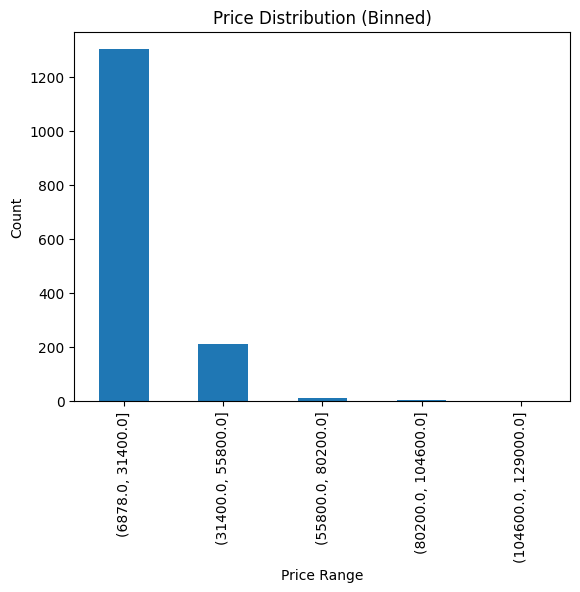

In [9]:
price_bins = pd.cut(target_train, bins=5)
bin_counts = price_bins.value_counts().sort_index()

print(bin_counts)

bin_counts.plot(kind='bar', title='Price Distribution (Binned)')
plt.xlabel('Price Range')
plt.ylabel('Count')
plt.show()


# Dataset Bin-Based OverSampling (to balance classes) :

In [10]:
# 1. Create bins
price_bins = pd.cut(target_train, bins=5)

# 2. Convert train set to DataFrame for resampling
train_df = features_train.copy()
train_df["price"] = target_train
train_df["bin"] = price_bins

# 3. Get the largest bin size
bin_counts = train_df["bin"].value_counts()
max_bin_size = bin_counts.max()

# 4. Oversample small bins
balanced_df = []

for b in bin_counts.index:
    df_bin = train_df[train_df["bin"] == b]
    df_upsampled = resample(
        df_bin,
        replace=True,
        n_samples=max_bin_size,
        random_state=42
    )
    balanced_df.append(df_upsampled)

balanced_df = pd.concat(balanced_df)

# 5. Extract resampled X and y
features_train_balanced = balanced_df.drop(columns=["price", "bin"])
target_train_balanced = balanced_df["price"]

print("Before balancing:", bin_counts)
print("\nAfter balancing:", balanced_df["bin"].value_counts())


Before balancing: bin
(6878.0, 31400.0]       1301
(31400.0, 55800.0]       213
(55800.0, 80200.0]        13
(80200.0, 104600.0]        3
(104600.0, 129000.0]       1
Name: count, dtype: int64

After balancing: bin
(6878.0, 31400.0]       1301
(31400.0, 55800.0]      1301
(55800.0, 80200.0]      1301
(80200.0, 104600.0]     1301
(104600.0, 129000.0]    1301
Name: count, dtype: int64


# Plot After Resampling :

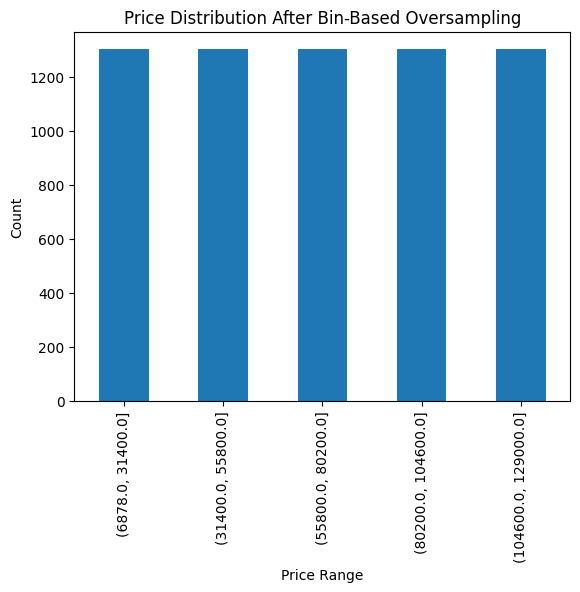

In [11]:
balanced_df["bin"].value_counts().sort_index().plot(
    kind='bar',
    title='Price Distribution After Bin-Based Oversampling'
)

plt.xlabel('Price Range')
plt.ylabel('Count')
plt.show()



# Feature Scaling :

In [12]:
scaler = StandardScaler()
numerical_cols = ['year', 'mileage', 'tax', 'mpg', 'engineSize']

features_train[numerical_cols] = scaler.fit_transform(features_train[numerical_cols])
features_test[numerical_cols] = scaler.transform(features_test[numerical_cols])

features_train.head()

,model,year,transmission,mileage,fuelType,tax,mpg,engineSize
1299,0,-1.818175,1,1.168040,0,-1.938664,2.019854,0.187851
1241,4,-1.818175,1,2.313664,0,0.042919,0.499224,0.187851
1507,9,-0.012970,2,0.979352,0,1.231869,-0.456860,0.187851
428,2,-0.012970,2,0.314317,0,-1.463084,0.972714,0.187851
1849,3,-1.818175,2,3.032325,0,0.359972,0.107685,0.187851


# Simple Linear Regression & Correlation Matrix


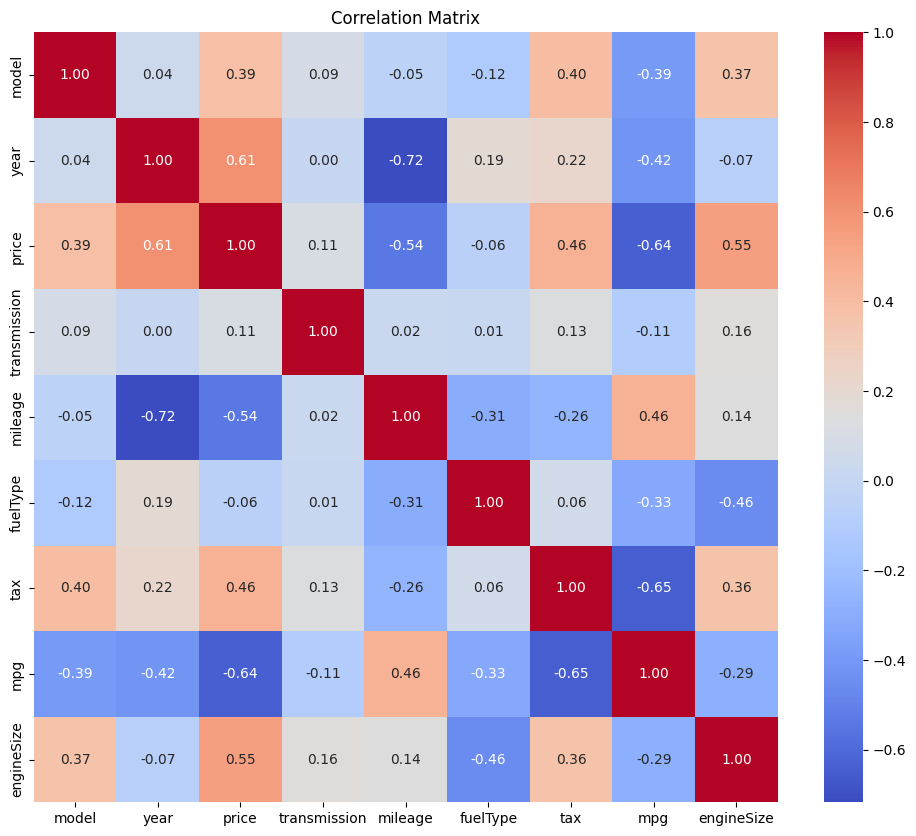


Best feature with Price: mpg


In [13]:
df_encoded = pd.get_dummies(df, drop_first=True)

# --- Compute correlation matrix ---
corr = df_encoded.corr(numeric_only=True)

# --- Visualize correlation matrix ---
plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

# --- Find the best correlated feature with price ---
best_feature = corr['price'].drop('price').abs().sort_values(ascending=False).index[0]
print(f"\nBest feature with Price: {best_feature}")


# --- Prepare train and test using the best feature ---
X_train_s = features_train[[best_feature]]
X_test_s  = features_test[[best_feature]]

# --- Fit Simple Linear Regression ---
model_s = LinearRegression()
model_s.fit(X_train_s, target_train)

# --- Predict, ensuring non-negative predictions ---
pred_s = np.maximum(model_s.predict(X_test_s), 0)


# Single Linear Metrics:


===== SIMPLE LINEAR REGRESSION (Regression View) =====
 R^2   = 0.455
 MAE   = 5264.420
 RMSE  = 7354.351


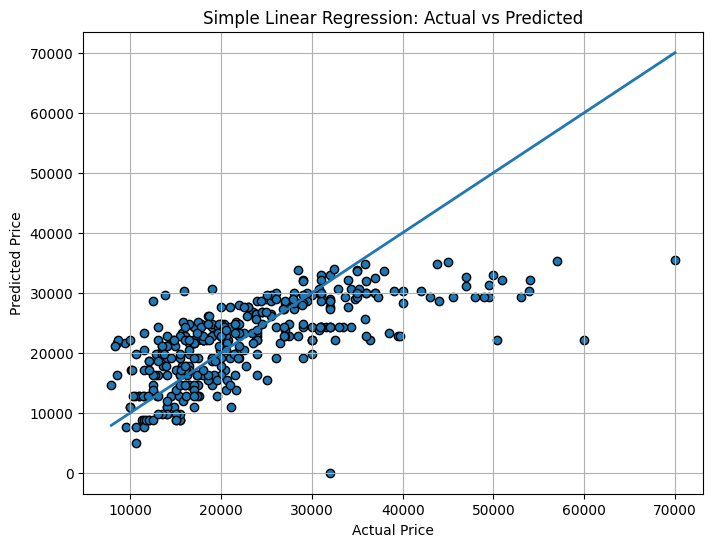

In [14]:


# ---- SLR METRICS (Regression View) ----
print("\n===== SIMPLE LINEAR REGRESSION (Regression View) =====")
print(f" R^2   = {r2_score(target_test, pred_s):.3f}")
print(f" MAE   = {mean_absolute_error(target_test, pred_s):.3f}")
print(f" RMSE  = {np.sqrt(mean_squared_error(target_test, pred_s)):.3f}")

# ---- VISUALIZE SLR ACTUAL vs PREDICTED ----
plt.figure(figsize=(8,6))
plt.scatter(target_test, pred_s, edgecolor="k")
plt.plot([target_test.min(), target_test.max()], [target_test.min(), target_test.max()], linewidth=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Simple Linear Regression: Actual vs Predicted")
plt.grid()
plt.show()

# Multiple Linear Regression:

In [15]:
X_train_m = pd.get_dummies(features_train, drop_first=True)
X_test_m  = pd.get_dummies(features_test, drop_first=True)
X_train_m, X_test_m = X_train_m.align(X_test_m, join='left', axis=1, fill_value=0)

model_m = LinearRegression()
model_m.fit(X_train_m, target_train)
pred_m = np.maximum(model_m.predict(X_test_m), 0)

from sklearn.preprocessing import StandardScaler

numeric_cols = ['year', 'mileage', 'tax', 'mpg', 'engineSize']
scaler = StandardScaler()
X_train_m[numeric_cols] = scaler.fit_transform(X_train_m[numeric_cols])
X_test_m[numeric_cols] = scaler.transform(X_test_m[numeric_cols])


# Multiple Linear Metrics


===== MULTIPLE LINEAR REGRESSION (Regression View) =====
 R^2   = 0.830
 MAE   = 2930.044
 RMSE  = 4111.677


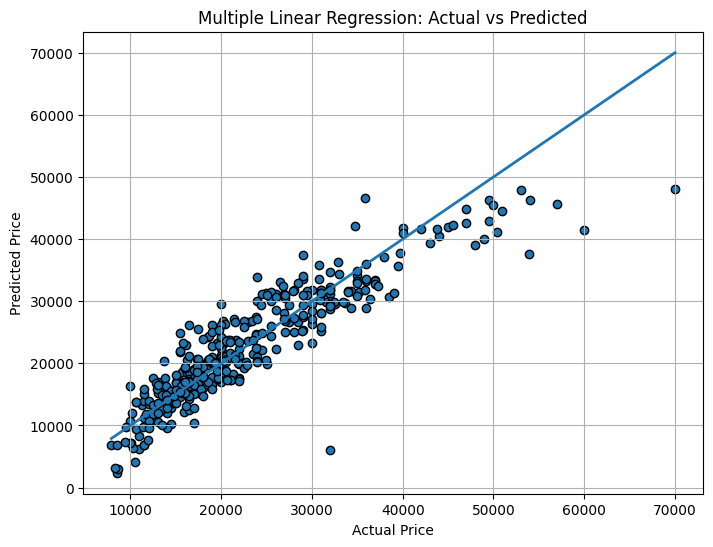

In [16]:
print("\n===== MULTIPLE LINEAR REGRESSION (Regression View) =====")
print(f" R^2   = {r2_score(target_test, pred_m):.3f}")
print(f" MAE   = {mean_absolute_error(target_test, pred_m):.3f}")
print(f" RMSE  = {np.sqrt(mean_squared_error(target_test, pred_m)):.3f}")


# ---- VISUALIZE MLR ACTUAL vs PREDICTED ----
plt.figure(figsize=(8,6))
plt.scatter(target_test, pred_m, edgecolor="k")
plt.plot([target_test.min(), target_test.max()], [target_test.min(), target_test.max()], linewidth=2)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Multiple Linear Regression: Actual vs Predicted")
plt.grid()
plt.show()

# SLR Actual vs Predict: 

In [17]:

print("\n===== SIMPLE LINEAR REGRESSION: ACTUAL vs PREDICTION =====")
pd.DataFrame({"Actual Price": target_test.values, "Predicted Price": pred_s}).head(20)




===== SIMPLE LINEAR REGRESSION: ACTUAL vs PREDICTION =====


,Actual Price,Predicted Price
0,35995.0,29951.935534
1,12995.0,19841.986380
2,14495.0,22193.137346
3,18498.0,26072.536440
4,13998.0,9849.594774
5,17498.0,19195.419864
6,29985.0,22193.137346
7,18998.0,19195.419864
8,14495.0,12847.312256
9,19751.0,23251.155281


# MLR Actual vs Predict:

In [18]:

print("\n===== SIMPLE LINEAR REGRESSION: ACTUAL vs PREDICTION =====")
pd.DataFrame({"Actual Price": target_test.values, "Predicted Price": pred_m}).head(20)



===== SIMPLE LINEAR REGRESSION: ACTUAL vs PREDICTION =====


,Actual Price,Predicted Price
0,35995.0,33204.802925
1,12995.0,12780.274627
2,14495.0,12845.355395
3,18498.0,24244.917939
4,13998.0,15174.924864
5,17498.0,17788.303548
6,29985.0,23341.279863
7,18998.0,16575.420233
8,14495.0,10282.846796
9,19751.0,20221.174119


# Model Testing:

In [19]:
print("\n==================== MODEL TESTS ====================")

# Test simple model
test_value = 55.4
simple_test_pred = model_s.predict(pd.DataFrame({best_feature: [test_value]}))[0]
print(f"\nSimple Model Prediction ({best_feature}={test_value}): £{simple_test_pred:,.2f}")
print("Simple Model R²:", r2_score(target_test, pred_s))

# Test multiple model
test_car = {
    "year": 2018,
    "mileage": 30000,
    "tax": 150,
    "mpg": 55.4,
    "engineSize": 2.0,
    "fuelType": "Petrol",
    "transmission": "Manual",
    "model": "A3"
}

test_df = pd.DataFrame([test_car])
test_df = pd.get_dummies(test_df, drop_first=True)
test_df = test_df.reindex(columns=X_train_m.columns, fill_value=0)

multi_test_pred = model_m.predict(test_df)[0]
print(f"\nMultiple Model Prediction: £{multi_test_pred:,.2f}")
print("Multiple Model R²:", r2_score(target_test, pred_m))

print("\n======================== END ========================")


==================== MODEL TESTS ====================

Simple Model Prediction (mpg=55.4): £-335,849.72
Simple Model R²: 0.45511696882506236

Multiple Model Prediction: £-65,398,891.60
Multiple Model R²: 0.8296851477202299

======================== END ========================
